In [1]:
import numpy as np
from numpy import arange
from numpy import mean
from numpy import std
import pandas as pd
import sklearn
import seaborn as sns
import re
import xgboost
import sklearn
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, StratifiedShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.linear_model import LogisticRegression

# ============================================================
# OUTPUT DIRECTORY
# ============================================================

outdir = Path(
    "~/Desktop/sex_differences/Blake Project/data/manuscript/figure5_ml"
).expanduser()

# Recursively create the directory if it does not exist
outdir.mkdir(
    parents=True,
    exist_ok=True
)

print(
    "Output directory:",
    outdir
)

covariates = pd.read_csv("~/Desktop/sex_differences/Blake Project/data/ML/model1_covariates.csv")
# rename sample id column
covariates.rename(columns={'Unnamed: 0':'sample_id'}, inplace=True)
# set sample_id column as index
covariates.set_index('sample_id', inplace=True)

microbes = pd.read_csv("~/Desktop/sex_differences/Blake Project/data/ML/model2_asvs_covariates.csv")
# rename sample id column
microbes.rename(columns={'Unnamed: 0':'sample_id'}, inplace=True)
# set sample_id column as index
microbes.set_index('sample_id', inplace=True)

kegg = pd.read_csv("~/Desktop/sex_differences/Blake Project/data/ML/model3_kegg_covariates.csv")
kegg.rename(columns={'Unnamed: 0':'sample_id'}, inplace=True)
# set sample_id column as index
kegg.set_index('sample_id', inplace=True)

ec = pd.read_csv("~/Desktop/sex_differences/Blake Project/data/ML/model4_ec_covariates.csv")
ec.rename(columns={'Unnamed: 0':'sample_id'}, inplace=True)
# set sample_id column as index
ec.set_index('sample_id', inplace=True)

pathway = pd.read_csv("~/Desktop/sex_differences/Blake Project/data/ML/model5_pathways_covariates.csv")
pathway.rename(columns={'Unnamed: 0':'sample_id'}, inplace=True)
# set sample_id column as index
pathway.set_index('sample_id', inplace=True)

microbes_keggs = pd.read_csv("~/Desktop/sex_differences/Blake Project/data/ML/model6_asvs_kegg_combined.csv")
microbes_keggs.rename(columns={'Unnamed: 0':'sample_id'}, inplace=True)
# set sample_id column as index
microbes_keggs.set_index('sample_id', inplace=True)

microbes_ecs = pd.read_csv("~/Desktop/sex_differences/Blake Project/data/ML/model7_asvs_ec_combined.csv")
microbes_ecs.rename(columns={'Unnamed: 0':'sample_id'}, inplace=True)
# set sample_id column as index
microbes_ecs.set_index('sample_id', inplace=True)

microbes_pws = pd.read_csv("~/Desktop/sex_differences/Blake Project/data/ML/model8_asvs_pathways_combined.csv")
microbes_pws.rename(columns={'Unnamed: 0':'sample_id'}, inplace=True)
# set sample_id column as index
microbes_pws.set_index('sample_id', inplace=True)

asvs_kegg_pw = pd.read_csv("~/Desktop/sex_differences/Blake Project/data/ML/model9_asvs_kegg_pathways_combined.csv")
asvs_kegg_pw.rename(columns={'Unnamed: 0':'sample_id'}, inplace=True)
# set sample_id column as index
asvs_kegg_pw.set_index('sample_id', inplace=True)

asvs_ec_pw = pd.read_csv("~/Desktop/sex_differences/Blake Project/data/ML/model10_asvs_ecs_pathways_combined.csv")
asvs_ec_pw.rename(columns={'Unnamed: 0':'sample_id'}, inplace=True)
# set sample_id column as index
asvs_ec_pw.set_index('sample_id', inplace=True)

datasets = [covariates, microbes, kegg, ec, pathway, microbes_keggs, microbes_ecs, microbes_pws, asvs_kegg_pw, asvs_ec_pw]
dataset_names = ['null', 'asvs', 'kegg', 'enzymes', 'pathways', 'asvs & keggs', 'asvs & ecs', 'asvs & pws', 'asvs, keggs, pathways', 'asvs, ecs, pathways']

# Set the default font to Arial
plt.rcParams['font.family'] = 'Arial'

for dataset, name in zip(datasets, dataset_names):
    print(name)
    print("N samples:", dataset.shape[0])
    print("Missing sex:", dataset["sex"].isna().sum())

    print(dataset["sex"].value_counts(dropna=False))
    print()

datasets_1 = [covariates, microbes, kegg, ec, pathway]
datasets_2 = [microbes_keggs, microbes_ecs, microbes_pws, asvs_kegg_pw, asvs_ec_pw]
dataset_1_names = ['Null', 'ASVs', 'KEGG', 'Enzymes (ECs)', 'MetaCyc Pathways']
dataset_2_names = ['ASVs, KEGG', 'ASVs, EC', 'ASVs, MetaCyc', 'ASVs, KEGG, MetaCyc', 'ASVs, EC, MetaCyc']
colors_1 = ['#595959', '#FDB462', '#8DD3C7', '#BC80BD', '#8C2155']
colors_2 = ['#E97C00', '#05B89A', '#B001B3', '#1E91D6', '#172A3A']

Output directory: /Users/blake/Desktop/sex_differences/Blake Project/data/manuscript/figure5_ml
null
N samples: 485
Missing sex: 0
sex
0    246
1    239
Name: count, dtype: int64

asvs
N samples: 485
Missing sex: 0
sex
0    246
1    239
Name: count, dtype: int64

kegg
N samples: 485
Missing sex: 0
sex
0    246
1    239
Name: count, dtype: int64

enzymes
N samples: 485
Missing sex: 0
sex
0    246
1    239
Name: count, dtype: int64

pathways
N samples: 485
Missing sex: 0
sex
0    246
1    239
Name: count, dtype: int64

asvs & keggs
N samples: 485
Missing sex: 0
sex
0    246
1    239
Name: count, dtype: int64

asvs & ecs
N samples: 485
Missing sex: 0
sex
0    246
1    239
Name: count, dtype: int64

asvs & pws
N samples: 485
Missing sex: 0
sex
0    246
1    239
Name: count, dtype: int64

asvs, keggs, pathways
N samples: 485
Missing sex: 0
sex
0    246
1    239
Name: count, dtype: int64

asvs, ecs, pathways
N samples: 485
Missing sex: 0
sex
0    246
1    239
Name: count, dtype: int64




Running Elastic-Net Logistic Regression: Null
Number of samples: 485
Number of predictors: 5

Class distribution:
sex
0    246
1    239
Name: count, dtype: int64
Missing predictor values: 0

---------- Outer fold 1 ----------
Train N: 388 | Test N: 97
Best inner-CV AUC: 0.5000
Best parameters: {'lr__C': np.float64(0.0001), 'lr__l1_ratio': 0.1}
Outer fold ROC AUC: 0.5000

---------- Outer fold 2 ----------
Train N: 388 | Test N: 97
Best inner-CV AUC: 0.5163
Best parameters: {'lr__C': np.float64(10.0), 'lr__l1_ratio': 0.1}
Outer fold ROC AUC: 0.4881

---------- Outer fold 3 ----------
Train N: 388 | Test N: 97
Best inner-CV AUC: 0.5463
Best parameters: {'lr__C': np.float64(100.0), 'lr__l1_ratio': 0.0}
Outer fold ROC AUC: 0.4681

---------- Outer fold 4 ----------
Train N: 388 | Test N: 97
Best inner-CV AUC: 0.5230
Best parameters: {'lr__C': np.float64(0.1), 'lr__l1_ratio': 0.5}
Outer fold ROC AUC: 0.5230

---------- Outer fold 5 ----------
Train N: 388 | Test N: 97
Best inner-CV AUC: 0.

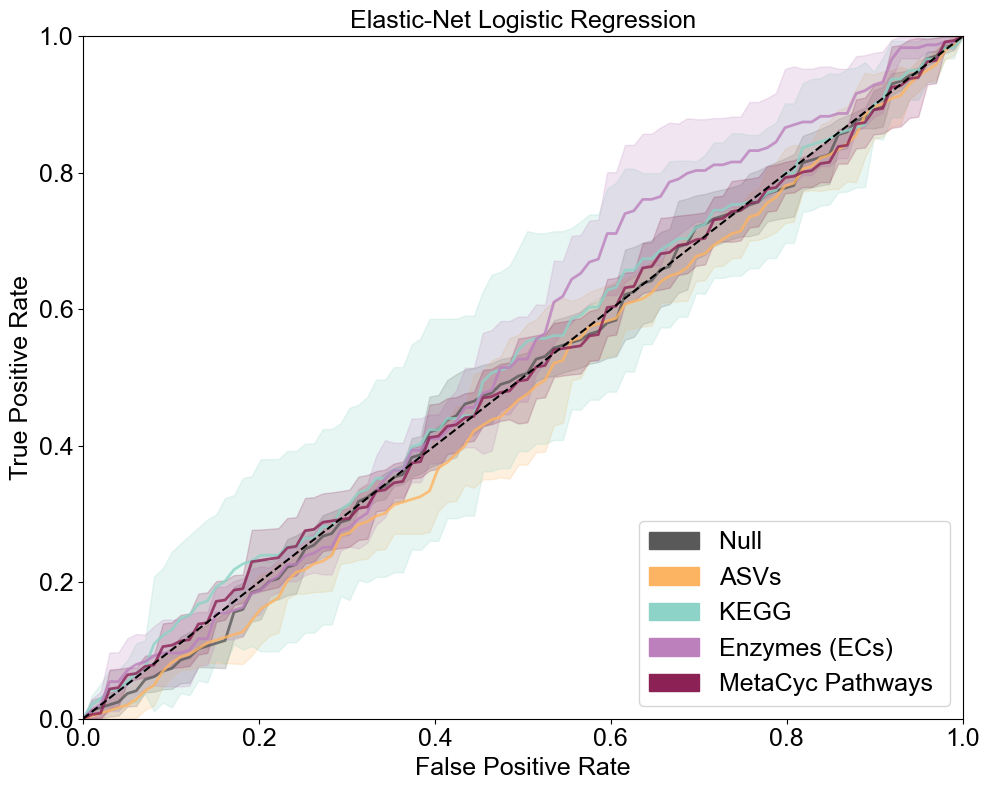


Running Elastic-Net Logistic Regression: ASVs, KEGG
Number of samples: 485
Number of predictors: 155

Class distribution:
sex
0    246
1    239
Name: count, dtype: int64
Missing predictor values: 0

---------- Outer fold 1 ----------
Train N: 388 | Test N: 97


KeyboardInterrupt: 

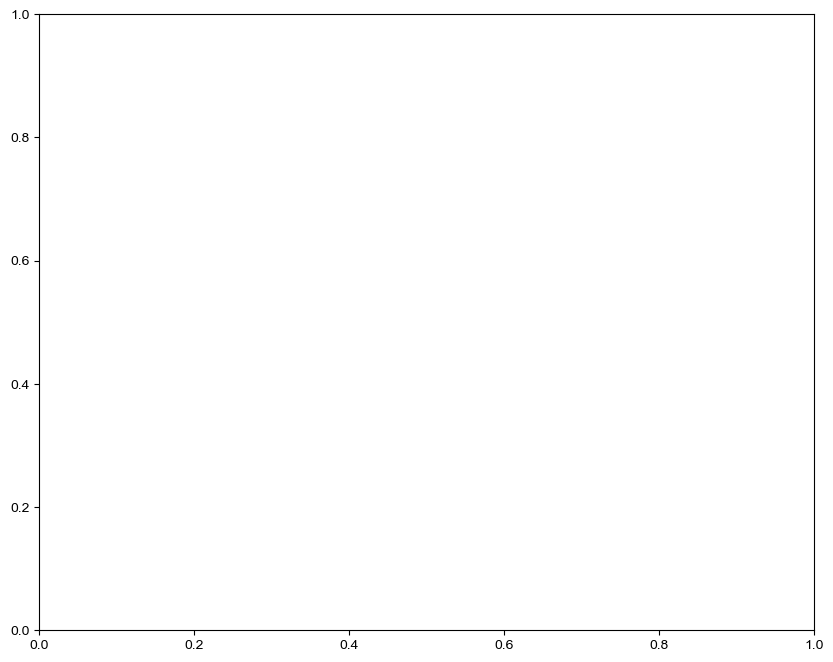

In [2]:
# ============================================================
# CROSS-VALIDATION
# ============================================================

outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

inner_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)

# ============================================================
# HYPERPARAMETER GRID
# ============================================================

param_grid = {
    "lr__C": np.logspace(
        -4,
        2,
        7
    ),
    "lr__l1_ratio": [
        0.0,
        0.10,
        0.25,
        0.50,
        0.75,
        0.90,
        1.0
    ]
}

# ============================================================
# FUNCTION:
# NESTED ELASTIC-NET CV + ROC FIGURE
# ============================================================

def run_elastic_net_group(
    datasets,
    dataset_names,
    colors,
    output_png,
    group_name
):

    fig, ax = plt.subplots(
        figsize=(10, 8)
    )

    legend_handles = []

    fold_results = []
    best_parameter_results = []
    oof_results = []

    # ========================================================
    # LOOP OVER DATASETS
    # ========================================================

    for dataset, name, color in zip(
        datasets,
        dataset_names,
        colors
    ):

        print(
            "\n============================================"
        )

        print(
            f"Running Elastic-Net Logistic Regression: {name}"
        )

        print(
            "============================================"
        )

        # ----------------------------------------------------
        # Remove samples missing the outcome
        # ----------------------------------------------------

        dataset_model = dataset.dropna(
            subset=["sex"]
        ).copy()

        # ----------------------------------------------------
        # Predictors and outcome
        # ----------------------------------------------------

        X = dataset_model.drop(
            columns=["sex"]
        )

        y = dataset_model["sex"]

        # ----------------------------------------------------
        # QC
        # ----------------------------------------------------

        print(
            "Number of samples:",
            len(y)
        )

        print(
            "Number of predictors:",
            X.shape[1]
        )

        print(
            "\nClass distribution:"
        )

        print(
            y.value_counts()
        )

        if y.nunique() != 2:
            raise ValueError(
                f"{name}: sex must contain exactly two classes."
            )

        if y.isna().any():
            raise ValueError(
                f"{name}: outcome still contains missing values."
            )

        non_numeric = X.select_dtypes(
            exclude=np.number
        ).columns.tolist()

        if len(non_numeric) > 0:
            raise ValueError(
                f"{name}: non-numeric predictors detected: "
                f"{non_numeric}"
            )

        print(
            "Missing predictor values:",
            X.isna().sum().sum()
        )

        # ====================================================
        # PIPELINE
        # ====================================================

        pipeline = Pipeline(
            steps=[
                (
                    "imputer",
                    SimpleImputer(
                        strategy="median"
                    )
                ),
                (
                    "variance",
                    VarianceThreshold(
                        threshold=0
                    )
                ),
                (
                    "scale",
                    StandardScaler()
                ),
                (
                    "lr",
                    LogisticRegression(
                        penalty="elasticnet",
                        solver="saga",
                        max_iter=10000,
                        random_state=42
                    )
                )
            ]
        )

        # ====================================================
        # OUTER-CV STORAGE
        # ====================================================

        outer_auc_scores = []

        mean_fpr = np.linspace(
            0,
            1,
            100
        )

        tprs = []

        # One unbiased prediction per sample
        oof_predictions = np.full(
            len(y),
            np.nan
        )

        # ====================================================
        # OUTER CROSS-VALIDATION
        # ====================================================

        for fold, (train_idx, test_idx) in enumerate(
            outer_cv.split(X, y),
            start=1
        ):

            print(
                f"\n---------- Outer fold {fold} ----------"
            )

            X_train = X.iloc[
                train_idx,
                :
            ]

            X_test = X.iloc[
                test_idx,
                :
            ]

            y_train = y.iloc[
                train_idx
            ]

            y_test = y.iloc[
                test_idx
            ]

            print(
                "Train N:",
                len(y_train),
                "| Test N:",
                len(y_test)
            )

            # ================================================
            # INNER CV HYPERPARAMETER TUNING
            # ================================================

            cv_lr = GridSearchCV(
                estimator=pipeline,
                param_grid=param_grid,
                scoring="roc_auc",
                cv=inner_cv,
                n_jobs=-1,
                verbose=0,
                refit=True
            )

            cv_lr.fit(
                X_train,
                y_train
            )

            best_model = cv_lr.best_estimator_

            print(
                f"Best inner-CV AUC: "
                f"{cv_lr.best_score_:.4f}"
            )

            print(
                "Best parameters:",
                cv_lr.best_params_
            )

            # ================================================
            # OUTER TEST PREDICTIONS
            # ================================================

            y_proba = best_model.predict_proba(
                X_test
            )[:, 1]

            oof_predictions[
                test_idx
            ] = y_proba

            # ================================================
            # OUTER-FOLD AUC
            # ================================================

            fold_auc = roc_auc_score(
                y_test,
                y_proba
            )

            outer_auc_scores.append(
                fold_auc
            )

            print(
                f"Outer fold ROC AUC: "
                f"{fold_auc:.4f}"
            )

            # ------------------------------------------------
            # Save fold results
            # ------------------------------------------------

            fold_results.append(
                {
                    "group": group_name,
                    "dataset": name,
                    "fold": fold,
                    "n_train": len(y_train),
                    "n_test": len(y_test),
                    "inner_auc": cv_lr.best_score_,
                    "outer_auc": fold_auc
                }
            )

            # ------------------------------------------------
            # Save optimal parameters
            # ------------------------------------------------

            best_parameter_results.append(
                {
                    "group": group_name,
                    "dataset": name,
                    "fold": fold,
                    "C": cv_lr.best_params_[
                        "lr__C"
                    ],
                    "l1_ratio": cv_lr.best_params_[
                        "lr__l1_ratio"
                    ]
                }
            )

            # ================================================
            # ROC CURVE FOR FOLD
            # ================================================

            fpr, tpr, _ = roc_curve(
                y_test,
                y_proba
            )

            interp_tpr = np.interp(
                mean_fpr,
                fpr,
                tpr
            )

            interp_tpr[0] = 0.0

            tprs.append(
                interp_tpr
            )

        # ====================================================
        # VERIFY OOF PREDICTIONS
        # ====================================================

        if np.isnan(
            oof_predictions
        ).any():

            raise ValueError(
                f"{name}: some samples are missing "
                "OOF predictions."
            )

        # ====================================================
        # POOLED OOF AUC
        # ====================================================

        pooled_oof_auc = roc_auc_score(
            y,
            oof_predictions
        )

        # ====================================================
        # FOLD SUMMARY
        # ====================================================

        mean_auc = np.mean(
            outer_auc_scores
        )

        sd_auc = np.std(
            outer_auc_scores,
            ddof=1
        )

        print(
            "\n============================================"
        )

        print(
            name
        )

        print(
            f"Mean fold AUC: "
            f"{mean_auc:.3f} ± {sd_auc:.3f}"
        )

        print(
            f"Pooled OOF AUC: "
            f"{pooled_oof_auc:.3f}"
        )

        print(
            "============================================"
        )

        # ====================================================
        # SAVE SAMPLE-LEVEL OOF PREDICTIONS
        # ====================================================

        for sample_id, true_y, pred_y in zip(
            X.index,
            y,
            oof_predictions
        ):

            oof_results.append(
                {
                    "group": group_name,
                    "dataset": name,
                    "sample": sample_id,
                    "sex": true_y,
                    "predicted_probability": pred_y
                }
            )

        # ====================================================
        # MEAN ROC
        # ====================================================

        mean_tpr = np.mean(
            tprs,
            axis=0
        )

        mean_tpr[-1] = 1.0

        std_tpr = np.std(
            tprs,
            axis=0
        )

        lower_tpr = np.maximum(
            mean_tpr - std_tpr,
            0
        )

        upper_tpr = np.minimum(
            mean_tpr + std_tpr,
            1
        )

        # ----------------------------------------------------
        # Plot
        # ----------------------------------------------------

        ax.plot(
            mean_fpr,
            mean_tpr,
            color=color,
            linewidth=2,
            alpha=0.8
        )

        ax.fill_between(
            mean_fpr,
            lower_tpr,
            upper_tpr,
            color=color,
            alpha=0.2
        )

        legend_handles.append(
            Patch(
                color=color,
                label=(
                    f"{name} "
                    #f"(OOF AUC = {pooled_oof_auc:.2f}; "
                    #f"fold SD = {sd_auc:.2f})"
                )
            )
        )

    # ========================================================
    # RANDOM-CHANCE LINE
    # ========================================================

    ax.plot(
        [0, 1],
        [0, 1],
        "k--",
        linewidth=1.5
    )

    # ========================================================
    # FIGURE FORMATTING
    # ========================================================

    ax.set_xlabel(
        "False Positive Rate",
        fontsize=18
    )

    ax.set_ylabel(
        "True Positive Rate",
        fontsize=18
    )

    ax.set_title(
        "Elastic-Net Logistic Regression",
        fontsize=18
    )

    ax.tick_params(
        axis="both",
        labelsize=18
    )

    ax.set_xlim(
        0,
        1
    )

    ax.set_ylim(
        0,
        1
    )

    ax.legend(
        handles=legend_handles,
        loc="lower right",
        fontsize=18
    )

    fig.tight_layout()

    # ========================================================
    # SAVE PNG
    # ========================================================

    fig.savefig(
        output_png,
        dpi=600,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    # ========================================================
    # RESULT TABLES
    # ========================================================

    fold_results_df = pd.DataFrame(
        fold_results
    )

    best_parameters_df = pd.DataFrame(
        best_parameter_results
    )

    oof_results_df = pd.DataFrame(
        oof_results
    )

    # ========================================================
    # AUC SUMMARY
    # ========================================================

    auc_summary_df = (
        fold_results_df
        .groupby(
            [
                "group",
                "dataset"
            ],
            sort=False
        )
        .agg(
            mean_fold_auc=(
                "outer_auc",
                "mean"
            ),
            sd_fold_auc=(
                "outer_auc",
                "std"
            ),
            min_fold_auc=(
                "outer_auc",
                "min"
            ),
            max_fold_auc=(
                "outer_auc",
                "max"
            ),
            n_folds=(
                "outer_auc",
                "size"
            )
        )
        .reset_index()
    )

    oof_auc_summary = (
        oof_results_df
        .groupby(
            [
                "group",
                "dataset"
            ],
            sort=False
        )
        .apply(
            lambda x: roc_auc_score(
                x["sex"],
                x["predicted_probability"]
            ),
            include_groups=False
        )
        .reset_index(
            name="oof_auc"
        )
    )

    auc_summary_df = auc_summary_df.merge(
        oof_auc_summary,
        on=[
            "group",
            "dataset"
        ],
        how="left"
    )

    return (
        fold_results_df,
        auc_summary_df,
        best_parameters_df,
        oof_results_df
    )

# ============================================================
# DATASET GROUP 1
# ============================================================

(
    fold_results_1,
    auc_summary_1,
    best_parameters_1,
    oof_results_1
) = run_elastic_net_group(
    datasets=datasets_1,
    dataset_names=dataset_1_names,
    colors=colors_1,
    output_png=outdir / "elastic_net_roc_group1.png",
    group_name="single feature sets"
)


# ============================================================
# DATASET GROUP 2
# ============================================================

(
    fold_results_2,
    auc_summary_2,
    best_parameters_2,
    oof_results_2
) = run_elastic_net_group(
    datasets=datasets_2,
    dataset_names=dataset_2_names,
    colors=colors_2,
    output_png=outdir / "elastic_net_roc_group2.png",
    group_name="combined feature sets"
)

# ============================================================
# COMBINE RESULTS
# ============================================================

fold_results_df = pd.concat(
    [
        fold_results_1,
        fold_results_2
    ],
    ignore_index=True
)

auc_summary_df = pd.concat(
    [
        auc_summary_1,
        auc_summary_2
    ],
    ignore_index=True
)

best_parameters_df = pd.concat(
    [
        best_parameters_1,
        best_parameters_2
    ],
    ignore_index=True
)

oof_results_df = pd.concat(
    [
        oof_results_1,
        oof_results_2
    ],
    ignore_index=True
)


# ============================================================
# WRITE RESULTS
# ============================================================

auc_summary_df.to_csv(
    outdir / "elastic_net_auc_summary.csv",
    index=False
)

fold_results_df.to_csv(
    outdir / "elastic_net_auc_by_fold.csv",
    index=False
)

best_parameters_df.to_csv(
    outdir / "elastic_net_best_parameters.csv",
    index=False
)

oof_results_df.to_csv(
    outdir / "elastic_net_oof_predictions.csv",
    index=False
)


# ============================================================
# PRINT AUC SUMMARY
# ============================================================

print(
    "\nAUC summary:"
)

print(
    auc_summary_df
)

Output directory: /Users/blake/Desktop/sex_differences/Blake Project/data/manuscript/figure5_ml

Running XGBoost: Null
Original samples: 485
Samples used: 485

Class distribution:
sex
0    246
1    239
Name: count, dtype: int64
Number of predictors: 5
Missing predictor values: 0

---------- Outer fold 1 ----------
Training samples: 388
Test samples: 97
Best inner-CV AUC: 0.513
Best parameters:
{'colsample_bytree': np.float64(0.5527471299151353), 'gamma': np.float64(2.282672852414551), 'learning_rate': np.float64(0.01119243779335428), 'max_depth': 5, 'min_child_weight': 10, 'n_estimators': 447, 'reg_alpha': np.float64(0.006046293018986844), 'reg_lambda': np.float64(34.20914404434174), 'subsample': np.float64(0.7088528997538541)}
Outer fold 1 ROC AUC: 0.5991

---------- Outer fold 2 ----------
Training samples: 388
Test samples: 97
Best inner-CV AUC: 0.5258
Best parameters:
{'colsample_bytree': np.float64(0.5879626263386727), 'gamma': np.float64(0.09037681807760434), 'learning_rate': np.

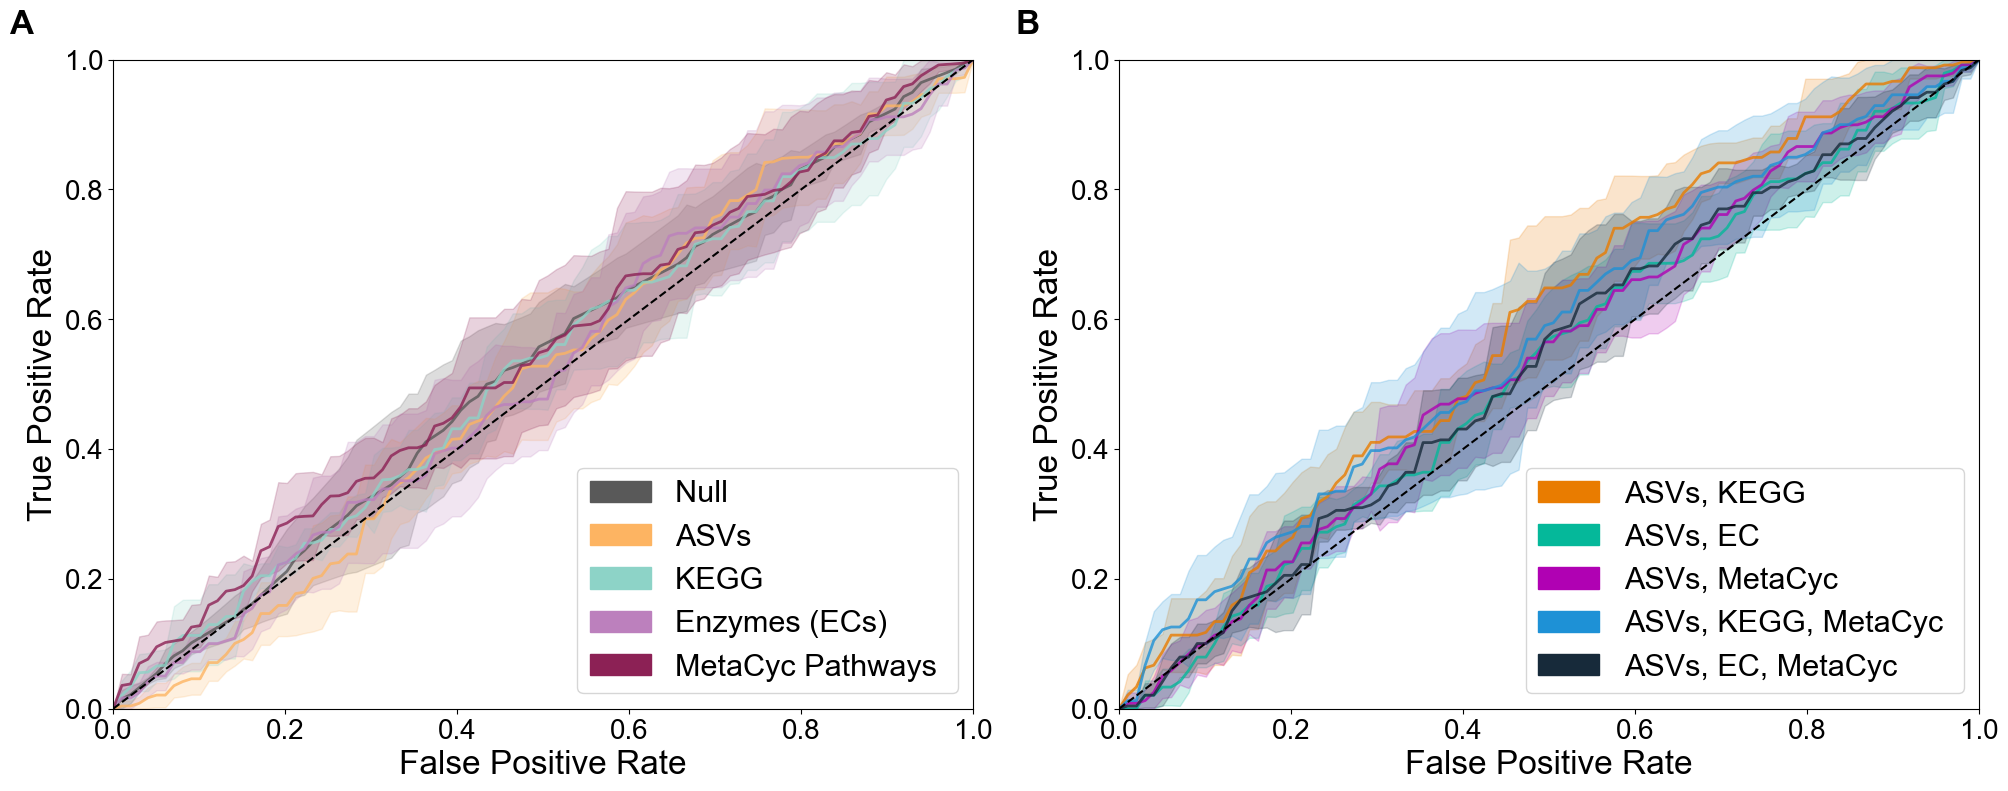


AUC summary:
                   group              dataset  mean_fold_auc  sd_fold_auc  \
0    single feature sets                 Null       0.528036     0.057354   
1    single feature sets                 ASVs       0.509491     0.056599   
2    single feature sets                 KEGG       0.525135     0.049842   
3    single feature sets        Enzymes (ECs)       0.517474     0.068290   
4    single feature sets     MetaCyc Pathways       0.546190     0.061131   
5  combined feature sets           ASVs, KEGG       0.588879     0.040532   
6  combined feature sets             ASVs, EC       0.528242     0.046435   
7  combined feature sets        ASVs, MetaCyc       0.542956     0.041869   
8  combined feature sets  ASVs, KEGG, MetaCyc       0.570772     0.079762   
9  combined feature sets    ASVs, EC, MetaCyc       0.533258     0.045898   

   min_fold_auc  max_fold_auc  n_folds   oof_auc  
0      0.443665      0.599149        5  0.508785  
1      0.434736      0.561224       

In [7]:
# ============================================================
# XGBOOST WITH NESTED CROSS-VALIDATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.patches import Patch

from sklearn.model_selection import (
    StratifiedKFold,
    RandomizedSearchCV
)

from sklearn.metrics import (
    roc_auc_score,
    roc_curve
)

from xgboost import XGBClassifier

from scipy.stats import (
    randint,
    uniform,
    loguniform
)


# ============================================================
# OUTPUT DIRECTORY
# ============================================================

outdir = Path(
    "~/Desktop/sex_differences/Blake Project/data/manuscript/figure5_ml"
).expanduser()

outdir.mkdir(
    parents=True,
    exist_ok=True
)

print(
    "Output directory:",
    outdir
)

# ============================================================
# PLOT SETTINGS
# ============================================================

plt.rcParams.update({
    "font.family": "Arial",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none"
})

# ============================================================
# CROSS-VALIDATION
# ============================================================

outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

inner_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)


# ============================================================
# XGBOOST HYPERPARAMETER SEARCH SPACE
# ============================================================

param_distributions = {

    "max_depth": randint(
        2,
        7
    ),

    "min_child_weight": randint(
        1,
        11
    ),

    "gamma": uniform(
        loc=0,
        scale=5
    ),

    "subsample": uniform(
        loc=0.6,
        scale=0.4
    ),

    "colsample_bytree": uniform(
        loc=0.5,
        scale=0.5
    ),

    "learning_rate": loguniform(
        0.005,
        0.2
    ),

    "n_estimators": randint(
        100,
        800
    ),

    "reg_alpha": loguniform(
        1e-4,
        10
    ),

    "reg_lambda": loguniform(
        1e-3,
        100
    )
}

# ============================================================
# FUNCTION:
# RUN NESTED XGBOOST CV FOR ONE DATASET GROUP
# ============================================================

def run_xgboost_group(
    datasets,
    dataset_names,
    colors,
    output_png,
    group_name,
    ax=None
):
    # Create an individual figure only if an axis
    # was not provided
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 8))
        standalone = True
    else:
        fig = ax.figure
        standalone = False

    # fig, ax = plt.subplots(
    #     figsize=(10, 8)
    # )

    legend_handles = []

    fold_results = []
    best_parameter_results = []
    oof_results = []

    # ========================================================
    # LOOP THROUGH FEATURE DATASETS
    # ========================================================

    for dataset, name, color in zip(
        datasets,
        dataset_names,
        colors
    ):

        print(
            "\n============================================"
        )

        print(
            f"Running XGBoost: {name}"
        )

        print(
            "============================================"
        )

        # ----------------------------------------------------
        # Remove samples with missing outcome
        # ----------------------------------------------------

        dataset_model = dataset.dropna(
            subset=["sex"]
        ).copy()

        print(
            "Original samples:",
            dataset.shape[0]
        )

        print(
            "Samples used:",
            dataset_model.shape[0]
        )

        # ----------------------------------------------------
        # Define predictors and outcome
        # ----------------------------------------------------

        X = dataset_model.drop(
            columns=["sex"]
        )

        y = dataset_model["sex"]

        # ----------------------------------------------------
        # QC
        # ----------------------------------------------------

        print(
            "\nClass distribution:"
        )

        print(
            y.value_counts()
        )

        if y.nunique() != 2:
            raise ValueError(
                f"{name}: sex must contain exactly two classes."
            )

        if y.isna().any():
            raise ValueError(
                f"{name}: y still contains missing values."
            )

        non_numeric = X.select_dtypes(
            exclude=np.number
        ).columns.tolist()

        if len(non_numeric) > 0:

            raise ValueError(
                f"{name}: non-numeric predictors detected: "
                f"{non_numeric}"
            )

        print(
            "Number of predictors:",
            X.shape[1]
        )

        print(
            "Missing predictor values:",
            X.isna().sum().sum()
        )

        # ====================================================
        # OUTER-CV STORAGE
        # ====================================================

        outer_auc_scores = []

        mean_fpr = np.linspace(
            0,
            1,
            100
        )

        tprs = []

        # Each sample gets one prediction from a model
        # that did not train on that sample
        oof_predictions = np.full(
            len(y),
            np.nan
        )

        # ====================================================
        # OUTER CROSS-VALIDATION
        # ====================================================

        for fold, (train_idx, test_idx) in enumerate(
            outer_cv.split(X, y),
            start=1
        ):

            print(
                f"\n---------- Outer fold {fold} ----------"
            )

            X_train = X.iloc[
                train_idx,
                :
            ]

            X_test = X.iloc[
                test_idx,
                :
            ]

            y_train = y.iloc[
                train_idx
            ]

            y_test = y.iloc[
                test_idx
            ]

            print(
                "Training samples:",
                len(y_train)
            )

            print(
                "Test samples:",
                len(y_test)
            )

            # ================================================
            # XGBOOST CLASSIFIER
            # ================================================

            classifier = XGBClassifier(
                objective="binary:logistic",
                eval_metric="logloss",
                tree_method="hist",
                random_state=42,
                n_jobs=1
            )

            # ================================================
            # INNER CV HYPERPARAMETER SEARCH
            # ================================================

            CV_xgb = RandomizedSearchCV(
                estimator=classifier,
                param_distributions=param_distributions,
                n_iter=50,
                scoring="roc_auc",
                cv=inner_cv,
                n_jobs=-1,
                random_state=42,
                verbose=0,
                refit=True
            )

            CV_xgb.fit(
                X_train,
                y_train
            )

            best_model = CV_xgb.best_estimator_

            print(
                "Best inner-CV AUC:",
                round(
                    CV_xgb.best_score_,
                    4
                )
            )

            print(
                "Best parameters:"
            )

            print(
                CV_xgb.best_params_
            )

            # ================================================
            # OUTER TEST-SET PREDICTIONS
            # ================================================

            y_proba = best_model.predict_proba(
                X_test
            )[:, 1]

            # Save OOF predictions
            oof_predictions[
                test_idx
            ] = y_proba

            # ================================================
            # OUTER TEST ROC-AUC
            # ================================================

            fold_auc = roc_auc_score(
                y_test,
                y_proba
            )

            outer_auc_scores.append(
                fold_auc
            )

            print(
                f"Outer fold {fold} ROC AUC: "
                f"{fold_auc:.4f}"
            )

            # ------------------------------------------------
            # Save fold results
            # ------------------------------------------------

            fold_results.append(
                {
                    "group": group_name,
                    "dataset": name,
                    "fold": fold,
                    "n_train": len(y_train),
                    "n_test": len(y_test),
                    "inner_auc": CV_xgb.best_score_,
                    "outer_auc": fold_auc
                }
            )

            # ------------------------------------------------
            # Save best hyperparameters
            # ------------------------------------------------

            params_row = {
                "group": group_name,
                "dataset": name,
                "fold": fold,
                "inner_auc": CV_xgb.best_score_
            }

            params_row.update(
                CV_xgb.best_params_
            )

            best_parameter_results.append(
                params_row
            )

            # ================================================
            # ROC CURVE FOR THIS OUTER FOLD
            # ================================================

            fpr, tpr, _ = roc_curve(
                y_test,
                y_proba
            )

            interp_tpr = np.interp(
                mean_fpr,
                fpr,
                tpr
            )

            interp_tpr[0] = 0.0

            tprs.append(
                interp_tpr
            )

        # ====================================================
        # VERIFY OOF PREDICTIONS
        # ====================================================

        if np.isnan(
            oof_predictions
        ).any():

            raise ValueError(
                f"{name}: some samples are missing "
                "OOF predictions."
            )

        # ====================================================
        # POOLED OOF AUC
        # ====================================================

        pooled_oof_auc = roc_auc_score(
            y,
            oof_predictions
        )

        # ====================================================
        # FOLD SUMMARY
        # ====================================================

        mean_auc = np.mean(
            outer_auc_scores
        )

        sd_auc = np.std(
            outer_auc_scores,
            ddof=1
        )

        print(
            "\n============================================"
        )

        print(
            name
        )

        print(
            f"Mean fold AUC: "
            f"{mean_auc:.3f} ± {sd_auc:.3f}"
        )

        print(
            f"Pooled OOF AUC: "
            f"{pooled_oof_auc:.3f}"
        )

        print(
            "============================================"
        )

        # ====================================================
        # SAVE SAMPLE-LEVEL OOF PREDICTIONS
        # ====================================================

        for sample_id, true_y, pred_y in zip(
            X.index,
            y,
            oof_predictions
        ):

            oof_results.append(
                {
                    "group": group_name,
                    "dataset": name,
                    "sample": sample_id,
                    "sex": true_y,
                    "predicted_probability": pred_y
                }
            )

        # ====================================================
        # MEAN ROC CURVE
        # ====================================================

        mean_tpr = np.mean(
            tprs,
            axis=0
        )

        mean_tpr[-1] = 1.0

        std_tpr = np.std(
            tprs,
            axis=0
        )

        lower_tpr = np.maximum(
            mean_tpr - std_tpr,
            0
        )

        upper_tpr = np.minimum(
            mean_tpr + std_tpr,
            1
        )

        # ----------------------------------------------------
        # Plot
        # ----------------------------------------------------

        ax.plot(
            mean_fpr,
            mean_tpr,
            color=color,
            linewidth=2,
            alpha=0.8
        )

        ax.fill_between(
            mean_fpr,
            lower_tpr,
            upper_tpr,
            color=color,
            alpha=0.2
        )

        legend_handles.append(
            Patch(
                color=color,
                label=(
                    f"{name} "
                    #f"(OOF AUC = {pooled_oof_auc:.2f}; "
                    #f"fold SD = {sd_auc:.2f})"
                )
            )
        )

    # ========================================================
    # RANDOM CHANCE
    # ========================================================

    ax.plot(
        [0, 1],
        [0, 1],
        "k--",
        linewidth=1.5
    )

    # ========================================================
    # FIGURE FORMATTING
    # ========================================================

    ax.set_xlabel(
        "False Positive Rate",
        fontsize=24
    )

    ax.set_ylabel(
        "True Positive Rate",
        fontsize=24
    )

    ax.set_title(
        "",
        fontsize=18
    )

    ax.tick_params(
        axis="both",
        labelsize=20
    )

    ax.set_xlim(
        0,
        1
    )

    ax.set_ylim(
        0,
        1
    )

    ax.legend(
        handles=legend_handles,
        loc="lower right",
        fontsize=22
    )

    # Save individual figures only when created separately
    if standalone:
        fig.tight_layout()

        fig.savefig(
            output_png,
            dpi=600,
            bbox_inches="tight"
        )

        print("Saved figure:", output_png)

        plt.show()
        plt.close(fig)

    # ========================================================
    # BUILD RESULT TABLES
    # ========================================================

    fold_results_df = pd.DataFrame(
        fold_results
    )

    best_parameters_df = pd.DataFrame(
        best_parameter_results
    )

    oof_results_df = pd.DataFrame(
        oof_results
    )

    # ========================================================
    # AUC SUMMARY
    # ========================================================

    auc_summary_df = (
        fold_results_df
        .groupby(
            [
                "group",
                "dataset"
            ],
            sort=False
        )
        .agg(
            mean_fold_auc=(
                "outer_auc",
                "mean"
            ),
            sd_fold_auc=(
                "outer_auc",
                "std"
            ),
            min_fold_auc=(
                "outer_auc",
                "min"
            ),
            max_fold_auc=(
                "outer_auc",
                "max"
            ),
            n_folds=(
                "outer_auc",
                "size"
            )
        )
        .reset_index()
    )

    # ========================================================
    # POOLED OOF AUC
    # ========================================================

    oof_auc_rows = []

    for (
        current_group,
        current_dataset
    ), current_df in oof_results_df.groupby(
        [
            "group",
            "dataset"
        ],
        sort=False
    ):

        current_auc = roc_auc_score(
            current_df["sex"],
            current_df["predicted_probability"]
        )

        oof_auc_rows.append(
            {
                "group": current_group,
                "dataset": current_dataset,
                "oof_auc": current_auc
            }
        )

    oof_auc_summary = pd.DataFrame(
        oof_auc_rows
    )

    auc_summary_df = auc_summary_df.merge(
        oof_auc_summary,
        on=[
            "group",
            "dataset"
        ],
        how="left"
    )

    return (
        fold_results_df,
        auc_summary_df,
        best_parameters_df,
        oof_results_df
    )

# ============================================================
# COMBINED XGBOOST ROC FIGURE
# ============================================================

# Create figure with two plots side by side
fig_combined, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(20, 8)
)

# ------------------------------------------------------------
# GROUP 1: Single feature sets
# ------------------------------------------------------------

(
    fold_results_1,
    auc_summary_1,
    best_parameters_1,
    oof_results_1
) = run_xgboost_group(
    datasets=datasets_1,
    dataset_names=dataset_1_names,
    colors=colors_1,
    output_png=outdir / "xgboost_roc_group1.png",
    group_name="single feature sets",
    ax=axes[0]
)

# ------------------------------------------------------------
# GROUP 2: Combined feature sets
# ------------------------------------------------------------

(
    fold_results_2,
    auc_summary_2,
    best_parameters_2,
    oof_results_2
) = run_xgboost_group(
    datasets=datasets_2,
    dataset_names=dataset_2_names,
    colors=colors_2,
    output_png=outdir / "xgboost_roc_group2.png",
    group_name="combined feature sets",
    ax=axes[1]
)

# ------------------------------------------------------------
# Figure formatting
# ------------------------------------------------------------

# Panel A
axes[0].text(
    -0.12, 1.04, "A",
    transform=axes[0].transAxes,
    fontsize=24,
    fontweight="bold"
)

# Panel B
axes[1].text(
    -0.12, 1.04, "B",
    transform=axes[1].transAxes,
    fontsize=24,
    fontweight="bold"
)

# Remove subplot titles
axes[0].set_title("")
axes[1].set_title("")

fig_combined.tight_layout(
    w_pad=3
)

# ------------------------------------------------------------
# Save vector PDF
# ------------------------------------------------------------

fig_combined.savefig(
    outdir / "xgboost_roc_combined.pdf",
    format="pdf",
    bbox_inches="tight"
)

# ------------------------------------------------------------
# Save high-resolution PNG
# ------------------------------------------------------------

fig_combined.savefig(
    outdir / "xgboost_roc_combined.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()
plt.close(fig_combined)

# # ============================================================
# # RUN DATASET GROUP 1
# # ============================================================

# (
#     fold_results_1,
#     auc_summary_1,
#     best_parameters_1,
#     oof_results_1
# ) = run_xgboost_group(
#     datasets=datasets_1,
#     dataset_names=dataset_1_names,
#     colors=colors_1,
#     output_png=outdir / "xgboost_roc_group1.png",
#     group_name="single feature sets"
# )


# # ============================================================
# # RUN DATASET GROUP 2
# # ============================================================

# (
#     fold_results_2,
#     auc_summary_2,
#     best_parameters_2,
#     oof_results_2
# ) = run_xgboost_group(
#     datasets=datasets_2,
#     dataset_names=dataset_2_names,
#     colors=colors_2,
#     output_png=outdir / "xgboost_roc_group2.png",
#     group_name="combined feature sets"
# )


# ============================================================
# COMBINE RESULTS
# ============================================================

fold_results_df = pd.concat(
    [
        fold_results_1,
        fold_results_2
    ],
    ignore_index=True
)

auc_summary_df = pd.concat(
    [
        auc_summary_1,
        auc_summary_2
    ],
    ignore_index=True
)

best_parameters_df = pd.concat(
    [
        best_parameters_1,
        best_parameters_2
    ],
    ignore_index=True
)

oof_results_df = pd.concat(
    [
        oof_results_1,
        oof_results_2
    ],
    ignore_index=True
)


# ============================================================
# SAVE TABLES
# ============================================================

auc_summary_df.to_csv(
    outdir / "xgboost_auc_summary.csv",
    index=False
)

fold_results_df.to_csv(
    outdir / "xgboost_auc_by_fold.csv",
    index=False
)

best_parameters_df.to_csv(
    outdir / "xgboost_best_parameters.csv",
    index=False
)

oof_results_df.to_csv(
    outdir / "xgboost_oof_predictions.csv",
    index=False
)


# ============================================================
# PRINT RESULTS
# ============================================================

print(
    "\nAUC summary:"
)

print(
    auc_summary_df
)

print(
    "\nSaved results to:"
)

print(
    outdir
)

Output directory: /Users/blake/Desktop/sex_differences/Blake Project/data/manuscript/figure5_ml

Running Random Forest: null
Number of samples: 485
Number of predictors: 5

Class distribution:
sex
0    246
1    239
Name: count, dtype: int64
Missing predictor values: 0

---------- Outer fold 1 ----------
Train N: 388 | Test N: 97
Best inner-CV AUC: 0.4774
Best parameters: {'rf__bootstrap': False, 'rf__criterion': 'log_loss', 'rf__max_depth': 3, 'rf__max_features': 'sqrt', 'rf__min_samples_leaf': 2, 'rf__min_samples_split': 10, 'rf__n_estimators': 865}
Outer fold ROC AUC: 0.6600

---------- Outer fold 2 ----------
Train N: 388 | Test N: 97
Best inner-CV AUC: 0.5257
Best parameters: {'rf__bootstrap': True, 'rf__criterion': 'entropy', 'rf__max_depth': 4, 'rf__max_features': 0.25, 'rf__min_samples_leaf': 2, 'rf__min_samples_split': 5, 'rf__n_estimators': 1026}
Outer fold ROC AUC: 0.4919

---------- Outer fold 3 ----------
Train N: 388 | Test N: 97
Best inner-CV AUC: 0.5764
Best parameters: 

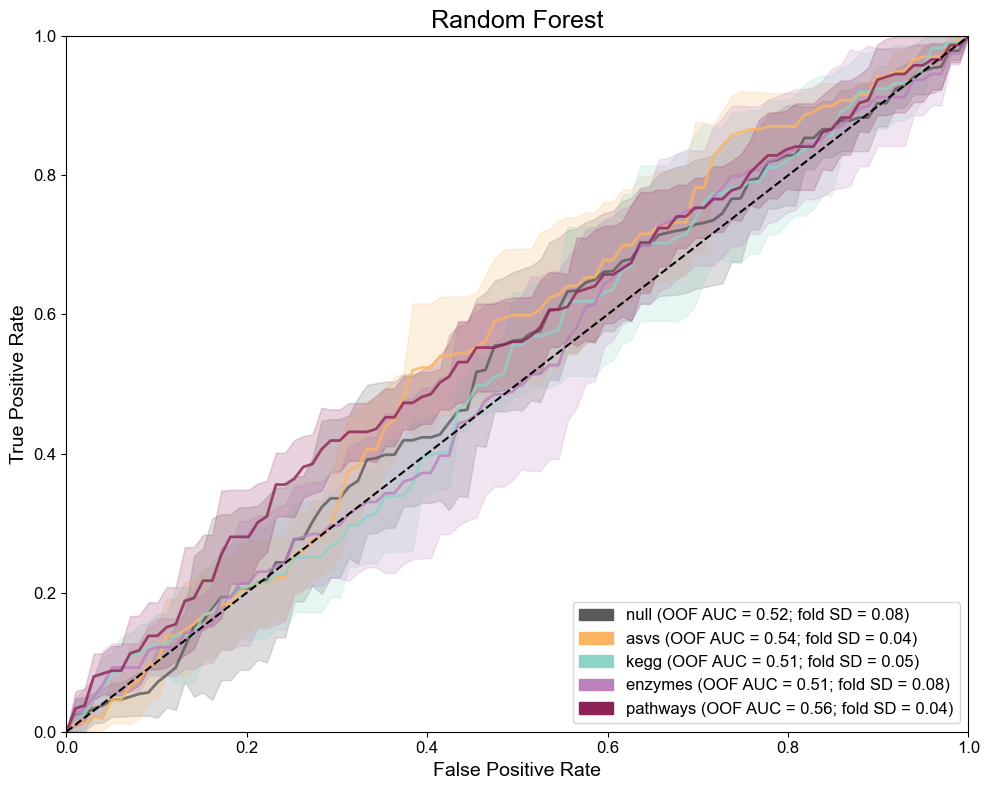


Running Random Forest: asvs & keggs
Number of samples: 485
Number of predictors: 155

Class distribution:
sex
0    246
1    239
Name: count, dtype: int64
Missing predictor values: 0

---------- Outer fold 1 ----------
Train N: 388 | Test N: 97
Best inner-CV AUC: 0.5821
Best parameters: {'rf__bootstrap': True, 'rf__criterion': 'log_loss', 'rf__max_depth': None, 'rf__max_features': 0.1, 'rf__min_samples_leaf': 16, 'rf__min_samples_split': 5, 'rf__n_estimators': 530}
Outer fold ROC AUC: 0.6409

---------- Outer fold 2 ----------
Train N: 388 | Test N: 97
Best inner-CV AUC: 0.5839
Best parameters: {'rf__bootstrap': True, 'rf__criterion': 'gini', 'rf__max_depth': 12, 'rf__max_features': 0.5, 'rf__min_samples_leaf': 16, 'rf__min_samples_split': 10, 'rf__n_estimators': 421}
Outer fold ROC AUC: 0.5914

---------- Outer fold 3 ----------
Train N: 388 | Test N: 97
Best inner-CV AUC: 0.6160
Best parameters: {'rf__bootstrap': True, 'rf__criterion': 'entropy', 'rf__max_depth': 3, 'rf__max_features

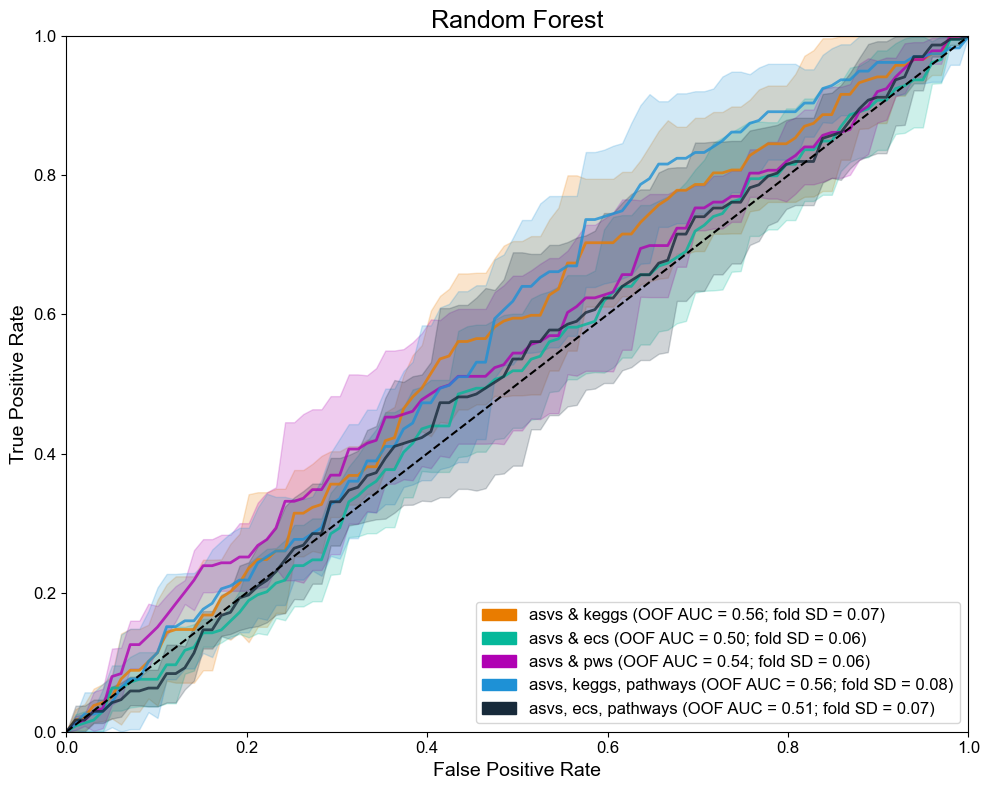


AUC summary:
                   group                dataset  mean_fold_auc  sd_fold_auc  \
0    single feature sets                   null       0.524730     0.078664   
1    single feature sets                   asvs       0.552059     0.042482   
2    single feature sets                   kegg       0.518374     0.049987   
3    single feature sets                enzymes       0.514969     0.082464   
4    single feature sets               pathways       0.558860     0.038503   
5  combined feature sets           asvs & keggs       0.558272     0.066074   
6  combined feature sets             asvs & ecs       0.507407     0.060317   
7  combined feature sets             asvs & pws       0.544832     0.057485   
8  combined feature sets  asvs, keggs, pathways       0.568136     0.075275   
9  combined feature sets    asvs, ecs, pathways       0.515315     0.071848   

   min_fold_auc  max_fold_auc  n_folds   oof_auc  
0      0.461735      0.660000        5  0.521967  
1      0.49192

In [4]:
# ============================================================
# RANDOM FOREST WITH NESTED CROSS-VALIDATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.patches import Patch

from sklearn.model_selection import (
    StratifiedKFold,
    RandomizedSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    roc_auc_score,
    roc_curve
)

from scipy.stats import randint


# ============================================================
# OUTPUT DIRECTORY
# ============================================================

outdir = Path(
    "~/Desktop/sex_differences/Blake Project/data/manuscript/figure5_ml"
).expanduser()

outdir.mkdir(
    parents=True,
    exist_ok=True
)

print(
    "Output directory:",
    outdir
)


# ============================================================
# CROSS-VALIDATION
# ============================================================

outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

inner_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)


# ============================================================
# RANDOM FOREST HYPERPARAMETER SEARCH SPACE
# ============================================================

param_distributions = {

    "rf__n_estimators": randint(
        300,
        1501
    ),

    "rf__max_depth": [
        None,
        3,
        4,
        5,
        6,
        8,
        10,
        12,
        15
    ],

    "rf__max_features": [
        "sqrt",
        "log2",
        0.10,
        0.25,
        0.50,
        0.75
    ],

    "rf__min_samples_split": [
        2,
        5,
        10,
        20
    ],

    "rf__min_samples_leaf": [
        1,
        2,
        4,
        8,
        16
    ],

    "rf__criterion": [
        "gini",
        "entropy",
        "log_loss"
    ],

    "rf__bootstrap": [
        True,
        False
    ]
}

# ============================================================
# FUNCTION:
# RUN NESTED RANDOM FOREST CV FOR ONE DATASET GROUP
# ============================================================

def run_random_forest_group(
    datasets,
    dataset_names,
    colors,
    output_png,
    group_name
):

    fig, ax = plt.subplots(
        figsize=(10, 8)
    )

    legend_handles = []

    fold_results = []
    best_parameter_results = []
    oof_results = []

    # ========================================================
    # LOOP OVER DATASETS
    # ========================================================

    for dataset, name, color in zip(
        datasets,
        dataset_names,
        colors
    ):

        print(
            "\n============================================"
        )

        print(
            f"Running Random Forest: {name}"
        )

        print(
            "============================================"
        )

        # ----------------------------------------------------
        # Remove samples with missing outcome
        # ----------------------------------------------------

        dataset_model = dataset.dropna(
            subset=["sex"]
        ).copy()

        # ----------------------------------------------------
        # Define predictors and outcome
        # ----------------------------------------------------

        X = dataset_model.drop(
            columns=["sex"]
        )

        y = dataset_model["sex"]

        # ----------------------------------------------------
        # QC
        # ----------------------------------------------------

        print(
            "Number of samples:",
            len(y)
        )

        print(
            "Number of predictors:",
            X.shape[1]
        )

        print(
            "\nClass distribution:"
        )

        print(
            y.value_counts()
        )

        if y.nunique() != 2:
            raise ValueError(
                f"{name}: sex must contain exactly two classes."
            )

        if y.isna().any():
            raise ValueError(
                f"{name}: outcome contains missing values."
            )

        non_numeric = X.select_dtypes(
            exclude=np.number
        ).columns.tolist()

        if len(non_numeric) > 0:

            raise ValueError(
                f"{name}: non-numeric predictors detected: "
                f"{non_numeric}"
            )

        print(
            "Missing predictor values:",
            X.isna().sum().sum()
        )

        # ====================================================
        # PIPELINE
        #
        # RF does not require scaling.
        # Imputation and zero-variance filtering stay inside CV.
        # ====================================================

        pipeline = Pipeline(
            steps=[
                (
                    "imputer",
                    SimpleImputer(
                        strategy="median"
                    )
                ),
                (
                    "variance",
                    VarianceThreshold(
                        threshold=0
                    )
                ),
                (
                    "rf",
                    RandomForestClassifier(
                        random_state=42,
                        n_jobs=1
                    )
                )
            ]
        )

        # ====================================================
        # OUTER-CV STORAGE
        # ====================================================

        outer_auc_scores = []

        mean_fpr = np.linspace(
            0,
            1,
            100
        )

        tprs = []

        oof_predictions = np.full(
            len(y),
            np.nan
        )

        # ====================================================
        # OUTER CROSS-VALIDATION
        # ====================================================

        for fold, (train_idx, test_idx) in enumerate(
            outer_cv.split(X, y),
            start=1
        ):

            print(
                f"\n---------- Outer fold {fold} ----------"
            )

            X_train = X.iloc[
                train_idx,
                :
            ]

            X_test = X.iloc[
                test_idx,
                :
            ]

            y_train = y.iloc[
                train_idx
            ]

            y_test = y.iloc[
                test_idx
            ]

            print(
                "Train N:",
                len(y_train),
                "| Test N:",
                len(y_test)
            )

            # ================================================
            # INNER-CV HYPERPARAMETER SEARCH
            # ================================================

            CV_rf = RandomizedSearchCV(
                estimator=pipeline,
                param_distributions=param_distributions,
                n_iter=60,
                scoring="roc_auc",
                cv=inner_cv,
                n_jobs=-1,
                random_state=42,
                verbose=0,
                refit=True
            )

            CV_rf.fit(
                X_train,
                y_train
            )

            best_model = CV_rf.best_estimator_

            print(
                f"Best inner-CV AUC: "
                f"{CV_rf.best_score_:.4f}"
            )

            print(
                "Best parameters:",
                CV_rf.best_params_
            )

            # ================================================
            # OUTER TEST-SET PREDICTION
            # ================================================

            y_proba = best_model.predict_proba(
                X_test
            )[:, 1]

            oof_predictions[
                test_idx
            ] = y_proba

            # ================================================
            # OUTER-FOLD ROC AUC
            # ================================================

            fold_auc = roc_auc_score(
                y_test,
                y_proba
            )

            outer_auc_scores.append(
                fold_auc
            )

            print(
                f"Outer fold ROC AUC: "
                f"{fold_auc:.4f}"
            )

            # ------------------------------------------------
            # Save fold-level results
            # ------------------------------------------------

            fold_results.append(
                {
                    "group": group_name,
                    "dataset": name,
                    "fold": fold,
                    "n_train": len(y_train),
                    "n_test": len(y_test),
                    "inner_auc": CV_rf.best_score_,
                    "outer_auc": fold_auc
                }
            )

            # ------------------------------------------------
            # Save best parameters
            # ------------------------------------------------

            parameter_row = {
                "group": group_name,
                "dataset": name,
                "fold": fold,
                "inner_auc": CV_rf.best_score_
            }

            parameter_row.update(
                CV_rf.best_params_
            )

            best_parameter_results.append(
                parameter_row
            )

            # ================================================
            # ROC CURVE FOR THIS OUTER FOLD
            # ================================================

            fpr, tpr, _ = roc_curve(
                y_test,
                y_proba
            )

            interp_tpr = np.interp(
                mean_fpr,
                fpr,
                tpr
            )

            interp_tpr[0] = 0.0

            tprs.append(
                interp_tpr
            )

        # ====================================================
        # VERIFY OOF PREDICTIONS
        # ====================================================

        if np.isnan(
            oof_predictions
        ).any():

            raise ValueError(
                f"{name}: some samples are missing "
                "OOF predictions."
            )

        # ====================================================
        # POOLED OUT-OF-FOLD AUC
        # ====================================================

        pooled_oof_auc = roc_auc_score(
            y,
            oof_predictions
        )

        # ====================================================
        # FOLD-LEVEL SUMMARY
        # ====================================================

        mean_auc = np.mean(
            outer_auc_scores
        )

        sd_auc = np.std(
            outer_auc_scores,
            ddof=1
        )

        print(
            "\n============================================"
        )

        print(
            name
        )

        print(
            f"Mean fold AUC: "
            f"{mean_auc:.3f} ± {sd_auc:.3f}"
        )

        print(
            f"Pooled OOF AUC: "
            f"{pooled_oof_auc:.3f}"
        )

        print(
            "============================================"
        )

        # ====================================================
        # SAVE SAMPLE-LEVEL OOF PREDICTIONS
        # ====================================================

        for sample_id, true_y, pred_y in zip(
            X.index,
            y,
            oof_predictions
        ):

            oof_results.append(
                {
                    "group": group_name,
                    "dataset": name,
                    "sample": sample_id,
                    "sex": true_y,
                    "predicted_probability": pred_y
                }
            )

        # ====================================================
        # MEAN ROC CURVE
        # ====================================================

        mean_tpr = np.mean(
            tprs,
            axis=0
        )

        mean_tpr[-1] = 1.0

        std_tpr = np.std(
            tprs,
            axis=0
        )

        lower_tpr = np.maximum(
            mean_tpr - std_tpr,
            0
        )

        upper_tpr = np.minimum(
            mean_tpr + std_tpr,
            1
        )

        # ----------------------------------------------------
        # Plot
        # ----------------------------------------------------

        ax.plot(
            mean_fpr,
            mean_tpr,
            color=color,
            linewidth=2,
            alpha=0.8
        )

        ax.fill_between(
            mean_fpr,
            lower_tpr,
            upper_tpr,
            color=color,
            alpha=0.2
        )

        legend_handles.append(
            Patch(
                color=color,
                label=(
                    f"{name} "
                    f"(OOF AUC = {pooled_oof_auc:.2f}; "
                    f"fold SD = {sd_auc:.2f})"
                )
            )
        )

    # ========================================================
    # RANDOM-CHANCE LINE
    # ========================================================

    ax.plot(
        [0, 1],
        [0, 1],
        "k--",
        linewidth=1.5
    )

    # ========================================================
    # FIGURE FORMATTING
    # ========================================================

    ax.set_xlabel(
        "False Positive Rate",
        fontsize=14
    )

    ax.set_ylabel(
        "True Positive Rate",
        fontsize=14
    )

    ax.set_title(
        "Random Forest",
        fontsize=18
    )

    ax.tick_params(
        axis="both",
        labelsize=12
    )

    ax.set_xlim(
        0,
        1
    )

    ax.set_ylim(
        0,
        1
    )

    ax.legend(
        handles=legend_handles,
        loc="lower right",
        fontsize=12
    )

    fig.tight_layout()

    # ========================================================
    # SAVE FIGURE
    # ========================================================

    fig.savefig(
        output_png,
        dpi=600,
        bbox_inches="tight"
    )

    print(
        "Saved figure:",
        output_png
    )

    plt.show()
    plt.close(fig)

    # ========================================================
    # RESULTS TABLES
    # ========================================================

    fold_results_df = pd.DataFrame(
        fold_results
    )

    best_parameters_df = pd.DataFrame(
        best_parameter_results
    )

    oof_results_df = pd.DataFrame(
        oof_results
    )

    # ========================================================
    # AUC SUMMARY
    # ========================================================

    auc_summary_df = (
        fold_results_df
        .groupby(
            [
                "group",
                "dataset"
            ],
            sort=False
        )
        .agg(
            mean_fold_auc=(
                "outer_auc",
                "mean"
            ),
            sd_fold_auc=(
                "outer_auc",
                "std"
            ),
            min_fold_auc=(
                "outer_auc",
                "min"
            ),
            max_fold_auc=(
                "outer_auc",
                "max"
            ),
            n_folds=(
                "outer_auc",
                "size"
            )
        )
        .reset_index()
    )

    # ========================================================
    # POOLED OOF AUC
    # ========================================================

    oof_auc_rows = []

    for (
        current_group,
        current_dataset
    ), current_df in oof_results_df.groupby(
        [
            "group",
            "dataset"
        ],
        sort=False
    ):

        current_auc = roc_auc_score(
            current_df["sex"],
            current_df["predicted_probability"]
        )

        oof_auc_rows.append(
            {
                "group": current_group,
                "dataset": current_dataset,
                "oof_auc": current_auc
            }
        )

    oof_auc_summary = pd.DataFrame(
        oof_auc_rows
    )

    auc_summary_df = auc_summary_df.merge(
        oof_auc_summary,
        on=[
            "group",
            "dataset"
        ],
        how="left"
    )

    return (
        fold_results_df,
        auc_summary_df,
        best_parameters_df,
        oof_results_df
    )


# ============================================================
# RUN DATASET GROUP 1
# ============================================================

(
    fold_results_1,
    auc_summary_1,
    best_parameters_1,
    oof_results_1
) = run_random_forest_group(
    datasets=datasets_1,
    dataset_names=dataset_1_names,
    colors=colors_1,
    output_png=outdir / "random_forest_roc_group1.png",
    group_name="single feature sets"
)


# ============================================================
# RUN DATASET GROUP 2
# ============================================================

(
    fold_results_2,
    auc_summary_2,
    best_parameters_2,
    oof_results_2
) = run_random_forest_group(
    datasets=datasets_2,
    dataset_names=dataset_2_names,
    colors=colors_2,
    output_png=outdir / "random_forest_roc_group2.png",
    group_name="combined feature sets"
)


# ============================================================
# COMBINE RESULTS
# ============================================================

fold_results_df = pd.concat(
    [
        fold_results_1,
        fold_results_2
    ],
    ignore_index=True
)

auc_summary_df = pd.concat(
    [
        auc_summary_1,
        auc_summary_2
    ],
    ignore_index=True
)

best_parameters_df = pd.concat(
    [
        best_parameters_1,
        best_parameters_2
    ],
    ignore_index=True
)

oof_results_df = pd.concat(
    [
        oof_results_1,
        oof_results_2
    ],
    ignore_index=True
)


# ============================================================
# SAVE TABLES
# ============================================================

auc_summary_df.to_csv(
    outdir / "random_forest_auc_summary.csv",
    index=False
)

fold_results_df.to_csv(
    outdir / "random_forest_auc_by_fold.csv",
    index=False
)

best_parameters_df.to_csv(
    outdir / "random_forest_best_parameters.csv",
    index=False
)

oof_results_df.to_csv(
    outdir / "random_forest_oof_predictions.csv",
    index=False
)


# ============================================================
# PRINT SUMMARY
# ============================================================

print(
    "\nAUC summary:"
)

print(
    auc_summary_df
)

print(
    "\nSaved results to:"
)

print(
    outdir
)